# 02 - Feature engineering

Question: do engineered features improve on the 19 raw attributes the deployed model uses?

**Protocol.** Same 80/20 stratified split as training (seed 42); **the test split is never touched here**.
Each candidate is added to the raw features and compared with the baseline using 3 x 5-fold repeated
stratified CV on the training part (PR-AUC and ROC-AUC). All variants use the *same folds*, so
differences are paired. XGBoost uses fixed moderate parameters (no per-variant tuning), so a feature
cannot win just because of luck in hyperparameters.

A feature is only worth adopting if the paired gain is clearly larger than its noise *and* it can be
computed from the prediction form inputs (the API receives only the raw attributes).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent          # notebooks/ lives one level below the project root
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4), "axes.titlesize": 11})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

from src.data.load import load_raw
from src.data.preprocess import clean
from src.features.build_features import CATEGORICAL, TARGET, build_features

df = clean(load_raw())
X, y = build_features(df), df[TARGET].astype(int).reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "| test (untouched):", X_test.shape)

train: (5634, 19) | test (untouched): (1409, 19)


## Candidate features

Motivated by the EDA: add-ons and billing behaviour looked informative, and `total_charges` is nearly
`tenure x monthly_charges`.

In [3]:
ADDONS = ["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]
PROTECT = ["online_security", "online_backup", "device_protection", "tech_support"]

def add_candidates(X):
    X = X.copy()
    n_addons = (X[ADDONS] == "Yes").sum(axis=1)
    has_internet = (X["internet_service"] != "No").astype(int)
    X["num_addons"] = n_addons
    X["num_protect"] = (X[PROTECT] == "Yes").sum(axis=1)            # security/support/backup/protection only
    X["has_internet"] = has_internet
    X["n_services"] = has_internet + X["phone_service"] + n_addons
    X["avg_monthly_spend"] = np.where(X["tenure"] > 0, X["total_charges"] / X["tenure"].clip(lower=1), X["monthly_charges"])
    X["charge_gap"] = X["total_charges"] - X["tenure"] * X["monthly_charges"]   # price change over the lifetime
    X["tenure_group"] = pd.cut(X["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)
    X["auto_pay"] = X["payment_method"].str.contains("automatic").astype(int)
    X["monthly_per_service"] = X["monthly_charges"] / (1 + X["n_services"])
    X["new_monthly"] = ((X["contract"] == "Month-to-month") & (X["tenure"] <= 12)).astype(int)
    return X

CANDIDATES = {
    "num_addons": ["num_addons"],
    "num_protect": ["num_protect"],
    "has_internet": ["has_internet"],
    "n_services": ["n_services"],
    "avg_monthly_spend": ["avg_monthly_spend"],
    "charge_gap": ["charge_gap"],
    "tenure_group": ["tenure_group"],
    "auto_pay": ["auto_pay"],
    "monthly_per_service": ["monthly_per_service"],
    "new_monthly (m2m & <=12m)": ["new_monthly"],
}
CANDIDATES["ALL candidates"] = sorted({c for v in list(CANDIDATES.values()) for c in v})
Xtr_all = add_candidates(X_train)
Xtr_all[["num_addons", "num_protect", "n_services", "avg_monthly_spend", "charge_gap", "monthly_per_service"]].describe().round(2)

,num_addons,num_protect,n_services,avg_monthly_spend,charge_gap,monthly_per_service
count,5634.00,5634.00,5634.00,5634.00,5634.00,5634.00
mean,2.06,1.28,3.74,64.94,0.04,13.76
std,1.85,1.29,2.11,30.22,67.45,4.10
min,0.00,0.00,1.00,13.83,-370.85,7.21
25%,0.00,0.00,2.00,36.05,-28.69,10.15
50%,2.00,1.00,4.00,70.59,0.00,12.75
75%,3.00,2.00,5.00,90.46,28.80,16.13
max,6.00,4.00,8.00,121.40,373.25,25.97


## Experiment

In [4]:
PARAMS = dict(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
              min_child_weight=5, tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=-1)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)   # identical folds for every variant

def evaluate(extra):
    cols = list(X_train.columns) + extra
    cat = [c for c in cols if c in CATEGORICAL or c == "tenure_group"]
    pipe = Pipeline([
        ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)], remainder="passthrough")),
        ("model", XGBClassifier(**PARAMS)),
    ])
    r = cross_validate(pipe, Xtr_all[cols], y_train, cv=cv, scoring={"pr": "average_precision", "roc": "roc_auc"})
    return r["test_pr"], r["test_roc"]

base_pr, base_roc = evaluate([])
rows = [("baseline (raw features)", base_pr.mean(), base_pr.std(), 0.0, 0.0, base_roc.mean(), 0.0)]
for name, extra in CANDIDATES.items():
    pr, roc = evaluate(extra)
    d = pr - base_pr                                   # paired per-fold differences
    rows.append((name, pr.mean(), pr.std(), d.mean(), d.std(ddof=1) / np.sqrt(len(d)), roc.mean(), (roc - base_roc).mean()))
res = pd.DataFrame(rows, columns=["variant", "PR-AUC", "PR sd", "d PR-AUC", "d SE", "ROC-AUC", "d ROC"]).set_index("variant")
res["d/SE"] = res["d PR-AUC"] / res["d SE"].replace(0, np.nan)
res.round(4)

,PR-AUC,PR sd,d PR-AUC,d SE,ROC-AUC,d ROC,d/SE
variant,,,,,,,
baseline (raw features),0.6704,0.0197,0.0000,0.0000,0.8496,0.0000,NaN
num_addons,0.6702,0.0192,-0.0002,0.0004,0.8493,-0.0003,-0.5189
num_protect,0.6701,0.0196,-0.0003,0.0004,0.8495,-0.0001,-0.7263
has_internet,0.6703,0.0191,-0.0001,0.0005,0.8493,-0.0003,-0.2186
n_services,0.6700,0.0193,-0.0004,0.0004,0.8494,-0.0002,-1.0642
avg_monthly_spend,0.6685,0.0202,-0.0019,0.0013,0.8489,-0.0007,-1.5311
charge_gap,0.6681,0.0211,-0.0023,0.0013,0.8491,-0.0005,-1.7432
tenure_group,0.6708,0.0197,0.0004,0.0005,0.8493,-0.0003,0.8111
auto_pay,0.6706,0.0196,0.0002,0.0006,0.8494,-0.0002,0.4018


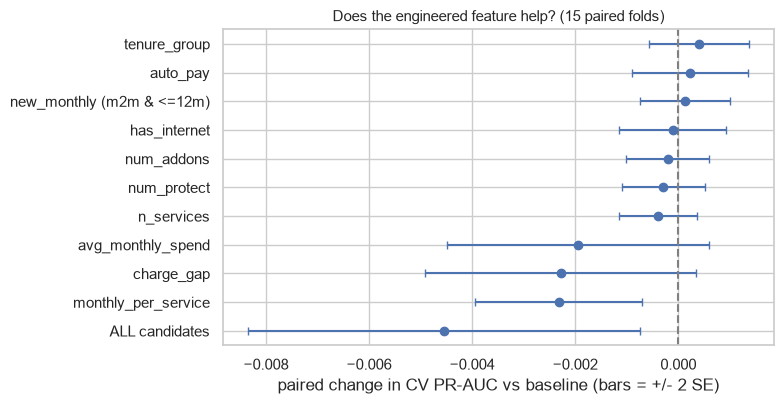

In [5]:
plot = res.drop("baseline (raw features)").sort_values("d PR-AUC")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(plot["d PR-AUC"], plot.index, xerr=2 * plot["d SE"], fmt="o", color="#4c72b0", capsize=3)
ax.axvline(0, color="grey", ls="--")
ax.set_xlabel("paired change in CV PR-AUC vs baseline (bars = +/- 2 SE)")
ax.set_title("Does the engineered feature help? (15 paired folds)")
plt.tight_layout(); plt.show()

## Do the new features carry information the model does not already have?

A quick check: how well does each candidate predict churn *alone*, and how correlated is it with the
raw features it was built from?

In [6]:
from sklearn.metrics import roc_auc_score
single = {}
for c in ["num_addons", "num_protect", "n_services", "avg_monthly_spend", "charge_gap", "monthly_per_service", "new_monthly", "auto_pay", "has_internet"]:
    a = roc_auc_score(y_train, Xtr_all[c])
    single[c] = max(a, 1 - a)                       # direction-free univariate AUC
for c in ["tenure", "monthly_charges", "total_charges"]:
    a = roc_auc_score(y_train, Xtr_all[c]); single[c + " (raw)"] = max(a, 1 - a)
print("single-feature ROC-AUC (direction-free):")
print(pd.Series(single).sort_values(ascending=False).round(3).to_string())
print()
print("corr(avg_monthly_spend, monthly_charges) =", round(Xtr_all["avg_monthly_spend"].corr(Xtr_all["monthly_charges"]), 3))
print("corr(num_addons, monthly_charges)        =", round(Xtr_all["num_addons"].corr(Xtr_all["monthly_charges"]), 3))

single-feature ROC-AUC (direction-free):
monthly_per_service      0.748
tenure (raw)             0.735
new_monthly              0.678
total_charges (raw)      0.645
avg_monthly_spend        0.624
monthly_charges (raw)    0.624
auto_pay                 0.623
has_internet             0.607
num_protect              0.595
num_addons               0.536
n_services               0.508
charge_gap               0.500

corr(avg_monthly_spend, monthly_charges) = 0.996
corr(num_addons, monthly_charges)        = 0.726


## Findings

- **No candidate improved the model.** Baseline CV PR-AUC is 0.6704; every single feature changes it by less than +/-0.003 (best: `tenure_group`, +0.0004, within noise). Adding **all** candidates at once *lowers* PR-AUC by 0.0045 (d/SE = -2.4), and `monthly_per_service` alone lowers it by 0.0023 (d/SE = -2.9).
- **Why:** the information is already in the raw columns, and gradient-boosted trees learn these combinations themselves. For example `avg_monthly_spend` is 0.996 correlated with `monthly_charges`, and `num_addons` is built from columns the model already sees. `charge_gap` has a univariate AUC of exactly 0.500, i.e. no signal on its own.
- **A strong single-feature signal does not mean a gain:** `monthly_per_service` has the best univariate ROC-AUC (0.748, above raw `tenure`) yet does not help, because tenure, charges and the service flags already let the model reconstruct it.
- **Caveat on the noise estimate:** the 15 folds overlap in their training data, so the standard errors above are optimistic. A difference of a few 0.001 should be read as "no evidence of a gain", not as a precise measurement.

## Decision

Keep the **19 raw features**. This is also the simplest choice for the product: the prediction form only needs raw attributes, and SHAP / LIME explain exactly those fields, with no derived columns to translate for the user.

Possible follow-ups (not done): interaction features for a *linear* model, target encoding, or dropping the weak features from the EDA (`gender`, `phone_service`, `multiple_lines`) to check whether the model gets simpler at no cost.